
This project builds a movie recommendation system similar to OTT platforms.
It uses a hybrid approach combining collaborative filtering and content-based filtering.
User ratings and movie genres are analyzed to understand user preferences.
The system recommends personalized movies to improve user experience.
The MovieLens dataset is used for implementation and analysis.

This cell loads the MovieLens dataset using pandas.
The data contains movie details and user ratings,
which are required to build the recommendation system.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
movies = pd.read_csv("movies.csv")
ratings = pd.read_csv("ratings.csv")

In [4]:
print(movies.shape)
print(movies.columns)
movies.head()

(9742, 3)
Index(['movieId', 'title', 'genres'], dtype='object')


,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy


In [5]:
print(ratings.shape)
print(ratings.columns)
ratings.head()

(100836, 4)
Index(['userId', 'movieId', 'rating', 'timestamp'], dtype='object')


,userId,movieId,rating,timestamp
0,1,1,4.0,964982703
1,1,3,4.0,964981247
2,1,6,4.0,964982224
3,1,47,5.0,964983815
4,1,50,5.0,964982931


In [6]:
print(movies.info())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9742 entries, 0 to 9741
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   movieId  9742 non-null   int64 
 1   title    9742 non-null   object
 2   genres   9742 non-null   object
dtypes: int64(1), object(2)
memory usage: 228.5+ KB
None


In [7]:
print(ratings.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100836 entries, 0 to 100835
Data columns (total 4 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   userId     100836 non-null  int64  
 1   movieId    100836 non-null  int64  
 2   rating     100836 non-null  float64
 3   timestamp  100836 non-null  int64  
dtypes: float64(1), int64(3)
memory usage: 3.1 MB
None


In [8]:
movies.isnull().sum()



movieId    0
title      0
genres     0
dtype: int64

In [9]:

ratings.isnull().sum()


userId       0
movieId      0
rating       0
timestamp    0
dtype: int64

In [10]:
ratings = ratings.drop('timestamp', axis=1)


Here, movie and rating data are combined into one dataset.
This helps in analyzing user behavior along with movie information.


The data is cleaned and prepared for analysis.
Preprocessing improves the accuracy of the recommendation system.

In [26]:
data = pd.merge(ratings, movies, on='movieId')
data.to_csv("merged_movies.csv", index=False)


In [ ]:
data.head()


,userId,movieId,rating,title,genres
0,1,1,4.0,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,1,3,4.0,Grumpier Old Men (1995),Comedy|Romance
2,1,6,4.0,Heat (1995),Action|Crime|Thriller
3,1,47,5.0,Seven (a.k.a. Se7en) (1995),Mystery|Thriller
4,1,50,5.0,"Usual Suspects, The (1995)",Crime|Mystery|Thriller


In [ ]:
data['genres'] = data['genres'].str.replace('|', ' ', regex=True)


This exploratory data analysis helps us understand user rating patterns
and identify popular movies in the dataset.
It gives useful insights before building the recommendation model.


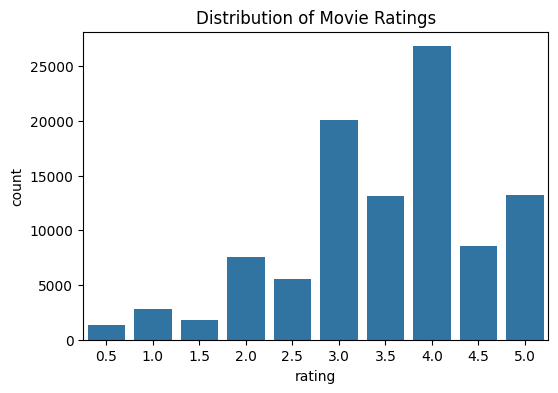

In [ ]:
#This graph shows how frequently users give different rating values.

plt.figure(figsize=(6,4))
sns.countplot(x='rating', data=ratings)
plt.title("Distribution of Movie Ratings")
plt.show()


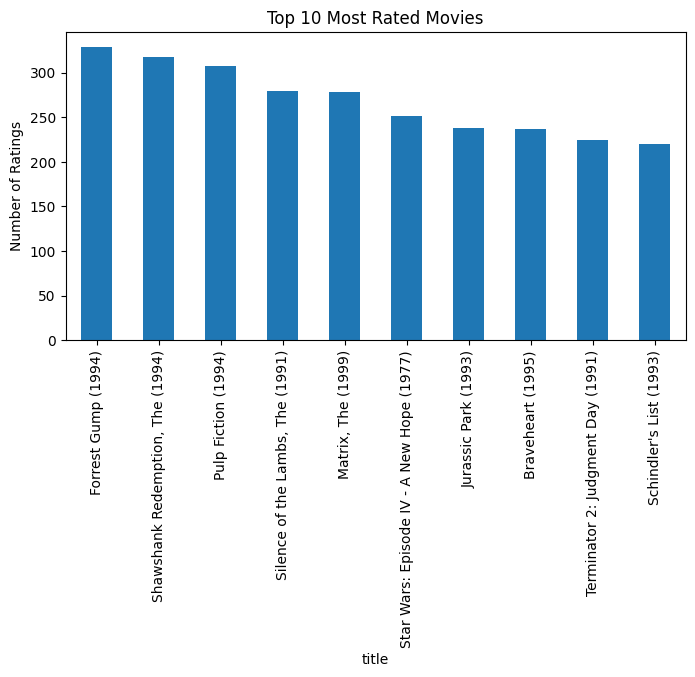

In [ ]:
#This graph displays the most popular movies based on user ratings.


top_movies = data.groupby('title')['rating'].count().sort_values(ascending=False).head(10)

plt.figure(figsize=(8,4))
top_movies.plot(kind='bar')
plt.title("Top 10 Most Rated Movies")
plt.ylabel("Number of Ratings")
plt.show()


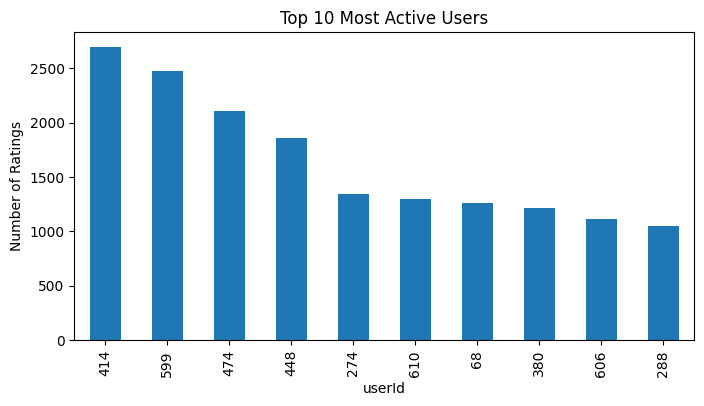

In [13]:
top_users = ratings['userId'].value_counts().head(10)

plt.figure(figsize=(8,4))
top_users.plot(kind='bar')
plt.title("Top 10 Most Active Users")
plt.ylabel("Number of Ratings")
plt.show()


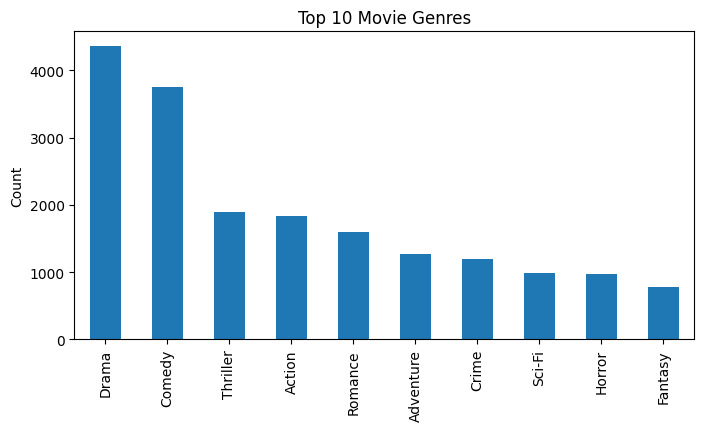

In [ ]:
#This graph shows which movie genres are most preferred by users.


genre_count = movies['genres'].str.split('|', expand=True).stack().value_counts().head(10)

plt.figure(figsize=(8,4))
genre_count.plot(kind='bar')
plt.title("Top 10 Movie Genres")
plt.ylabel("Count")
plt.show()


In [15]:
data.describe()


,userId,movieId,rating
count,100836.000000,100836.000000,100836.000000
mean,326.127564,19435.295718,3.501557
std,182.618491,35530.987199,1.042529
min,1.000000,1.000000,0.500000
25%,177.000000,1199.000000,3.000000
50%,325.000000,2991.000000,3.500000
75%,477.000000,8122.000000,4.000000
max,610.000000,193609.000000,5.000000


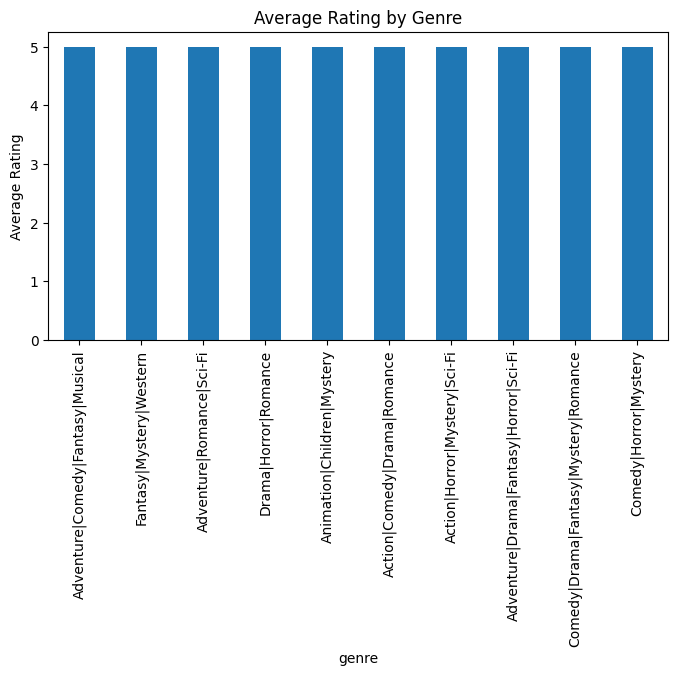

In [27]:
genre_data = data.copy()
genre_data['genre'] = genre_data['genres'].str.split(' ')
genre_data = genre_data.explode('genre')

avg_rating = genre_data.groupby('genre')['rating'].mean().sort_values(ascending=False).head(10)

plt.figure(figsize=(8,4))
avg_rating.plot(kind='bar')
plt.title("Average Rating by Genre")
plt.ylabel("Average Rating")
plt.show()


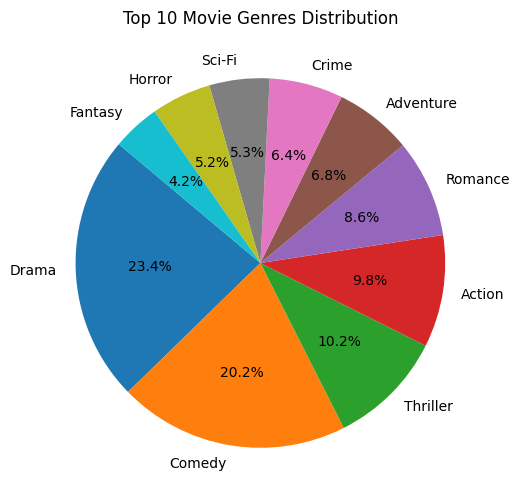

In [ ]:
#Top 10 Movie Genres Distribution

genre_count = movies['genres'].str.split('|', expand=True).stack().value_counts().head(10)

plt.figure(figsize=(6,6))
plt.pie(
    genre_count,
    labels=genre_count.index,
    autopct='%1.1f%%',
    startangle=140
)
plt.title("Top 10 Movie Genres Distribution")
plt.show()


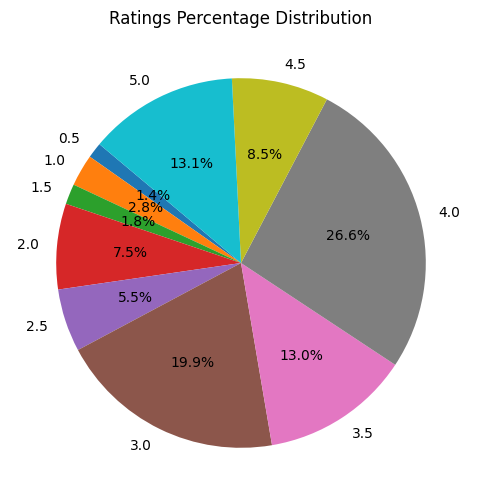

In [18]:
rating_count = ratings['rating'].value_counts().sort_index()

plt.figure(figsize=(6,6))
plt.pie(
    rating_count,
    labels=rating_count.index,
    autopct='%1.1f%%',
    startangle=140
)
plt.title("Ratings Percentage Distribution")
plt.show()


Correlation Heatmap

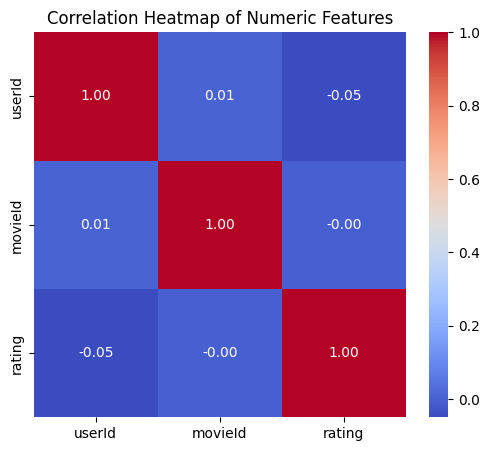

In [19]:
# Select numeric columns
numeric_cols = data.select_dtypes(include='number')

# Compute correlation matrix
corr_matrix = numeric_cols.corr()

# Plot heatmap
plt.figure(figsize=(6,5))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Correlation Heatmap of Numeric Features")
plt.show()


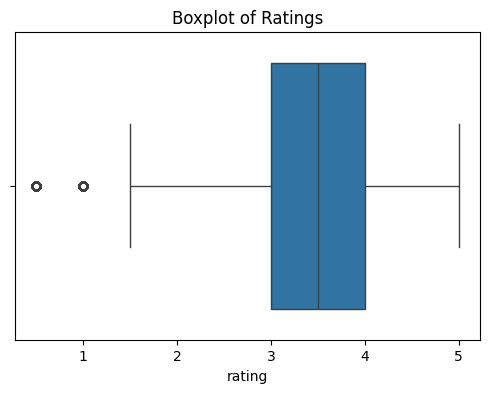

In [20]:
plt.figure(figsize=(6,4))
sns.boxplot(x='rating', data=ratings)
plt.title("Boxplot of Ratings")
plt.show()


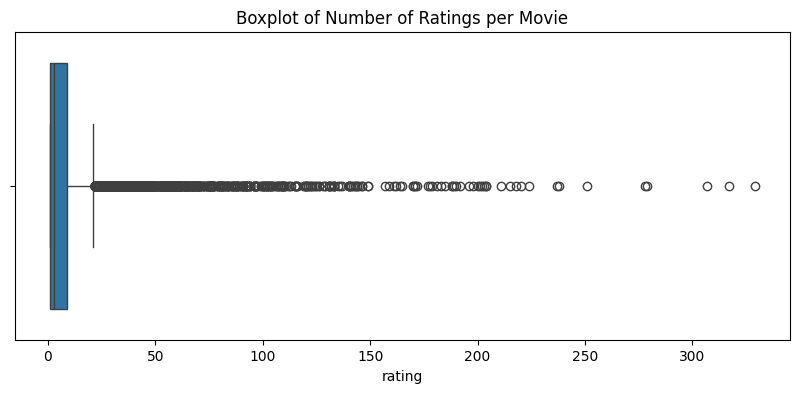

In [21]:
movie_counts = data.groupby('title')['rating'].count()

plt.figure(figsize=(10,4))
sns.boxplot(x=movie_counts)
plt.title("Boxplot of Number of Ratings per Movie")
plt.show()


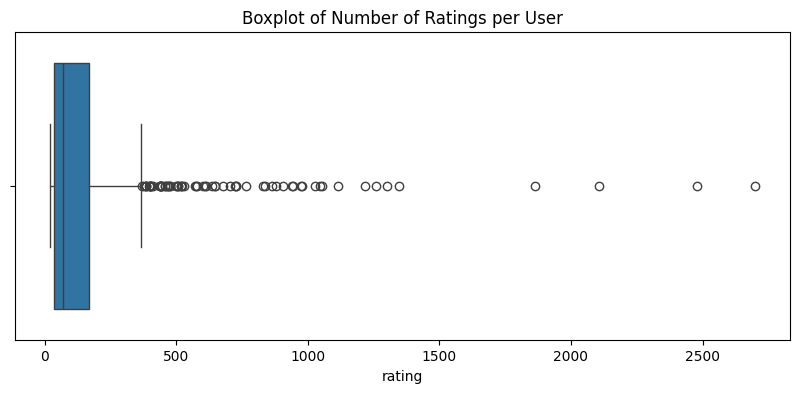

In [22]:
user_counts = data.groupby('userId')['rating'].count()

plt.figure(figsize=(10,4))
sns.boxplot(x=user_counts)
plt.title("Boxplot of Number of Ratings per User")
plt.show()


This script builds a hybrid movie recommendation system using a dataset of user ratings. It trains multiple machine learning models (Linear Regression, KNN, Random Forest, Gradient Boosting) to predict ratings and evaluates them using RMSE and MAE. It also computes user-based collaborative filtering using cosine similarity. Finally, it identifies the best ML model and saves it along with the user similarity matrix and pivot table as a hybrid model (`best_model.pkl`).


RMSE (Root Mean Squared Error) measures how far predicted ratings are from actual ratings.

Lower RMSE = better predictions (closer to true ratings); higher RMSE = worse predictions.


In [25]:
import pandas as pd
import numpy as np
import pickle
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics.pairwise import cosine_similarity

# Load dataset
data = pd.read_csv("merged_movies.csv")
data = data[['userId', 'movieId', 'rating']]

# Split data
X = data[['userId', 'movieId']]
y = data['rating']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

results = {}
models = {}

# Function to evaluate models
def evaluate_model(name, model):
    model.fit(X_train, y_train)
    preds = model.predict(X_test)
    
    rmse = np.sqrt(mean_squared_error(y_test, preds))
    mae = mean_absolute_error(y_test, preds)
    
    results[name] = {"RMSE": rmse, "MAE": mae}
    models[name] = model

# Train models
evaluate_model("Linear Regression", LinearRegression())
evaluate_model("KNN Regressor", KNeighborsRegressor(n_neighbors=5))
evaluate_model("Random Forest", RandomForestRegressor(n_estimators=50, random_state=42))
evaluate_model("Gradient Boosting", GradientBoostingRegressor())

# Collaborative Filtering (User-based)
pivot = data.pivot_table(index='userId', columns='movieId', values='rating').fillna(0)
user_similarity = cosine_similarity(pivot)

# Display results in a table
results_df = pd.DataFrame(results).T  # transpose for proper table
results_df = results_df.reset_index().rename(columns={'index': 'Model'})
print("\nModel Evaluation Metrics (RMSE & MAE):\n")
print(results_df)

# Identify best model
best_model_name = results_df.loc[results_df['RMSE'].idxmin(), 'Model']
best_model = models[best_model_name]
print("\nBest ML Model:", best_model_name)

# Save hybrid model
model_data = {
    "best_ml_model": best_model,
    "user_similarity": user_similarity,
    "pivot_table": pivot
}
pickle.dump(model_data, open("best_model.pkl", "wb"))
print("\nHybrid model saved as best_model.pkl")



Model Evaluation Metrics (RMSE & MAE):

               Model      RMSE       MAE
0  Linear Regression  1.047872  0.835158
1      KNN Regressor  1.070125  0.837212
2      Random Forest  1.059015  0.811824
3  Gradient Boosting  0.984736  0.776081

Best ML Model: Gradient Boosting

Hybrid model saved as best_model.pkl
